## Mini Batch

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

from utils import SIZE, CLASSES, prepare_data_set, plot_costs, load_image, get_label
from dnn import (
    relu, sigmoid, initialize_parameters, activate,
    ActivationCache, PropagateCache, ForwardCache,
    propagate, propagate_backward,
    AL_derivative, relu_backward, sigmoid_backward,
)

In [2]:
datasets = prepare_data_set()

Y_train = datasets["Y_train"]
X_train = datasets ["X_train"]
X_test = datasets["X_test"]
Y_test = datasets["Y_test"]
X_test_orig_set = datasets["X_test_orig_set"]
X_train_orig_set = datasets["X_train_orig_set"]

In [3]:
def forward_pass(X, parameters):
    # find the number of layers from the initialized parameters
    L = len(parameters) // 2

    # print(f"Len Layer: {L}")
    cache = [] # we need this later for backward propagation
    Aprev = X # initial assignment to A0
    for l in range(0,L):
        # here we calculate Zl     
        Zl, pc = propagate(parameters["W"+str(l+1)], Aprev, parameters["b"+str(l+1)])
        # here we calculate Al (it should be started from 1 by the loop)
        if (l == (L-1)): # for output layer, we use sigmoid
            Aprev, ac= activate(Zl, "sigmoid")
        else:
            Aprev, ac= activate(Zl, "relu")
        forward_cache = ForwardCache(PropagateCache = pc, ActivationCache=ac) 
        cache.append(forward_cache)
    output = Aprev
    # print(f"Len in forward: {len(cache)} {len(parameters)} ")
    return output, cache

In [4]:
def backward_pass(AL, Y, caches):

    grads = {}
    L = len(caches)
    current_layer_cache = caches[L-1]
    current_layer_W = current_layer_cache.PropagateCache.W
    current_layer_Aprev = current_layer_cache.PropagateCache.Aprev
    
    # get the dZ for outer/output layer
    # sigmoid + binary cross-entropy simplifies to dZ = AL - Y
    dZ = AL-Y
    dW,db, dAprev = propagate_backward(dZ, current_layer_Aprev, current_layer_W )
    grads["dW"+str(L)] = dW
    grads["db"+str(L)] = db

    # print(f"l in backward = {L}")
    
    for l in reversed (range (L-1)):
        current_layer_cache = caches[l]
        current_layer_W = current_layer_cache.PropagateCache.W
        current_layer_Aprev = current_layer_cache.PropagateCache.Aprev
        dZ = relu_backward(dAprev, current_layer_cache.ActivationCache)
        dW,db,dAprev = propagate_backward(dZ, current_layer_Aprev, current_layer_W)
        # print(f"l in backward = {l+1}")
        grads["dW" + str(l+1)] = dW
        grads["db" + str(l+1)] = db
    
    return grads

In [5]:
def calculate_cost(AL,Y):
    m = AL.shape[1]
    # clip AL to avoid log(0).
    AL = np.clip(AL, 1e-8, 1 - 1e-8)
    cost =  -(1./m) * np.sum((np.dot(Y,np.log(AL).T) + np.dot(1-Y, np.log(1-AL).T)))
    # make sure the output not a 0-dimensional array/scalar
    # eg 2D array (matrix) number: [[24]] => become 24.
    res = np.squeeze(cost)
    return res

In [6]:
def update_parameter(parameters, grads, learning_rate):

    # floor divide by 2 because each layer has both a 'W' and a 'b'
    L = len(parameters) // 2
    
    for l in range (0, L):
        parameters["W" + str(l+1)] = parameters["W" + str(l+1)] - (learning_rate * grads["dW"+str(l+1)])
        parameters["b" + str(l+1)] = parameters["b" + str(l+1)] - (learning_rate * grads["db"+str(l+1)])

    assert len(grads) == len(parameters)
    return parameters

In [7]:
def classify(X,parameters):
    output, _ = forward_pass(X,parameters)
    return (output > 0.5).astype(int)


def random_mini_batches(X, Y, mini_batch_size=64, seed=3):
    np.random.seed(seed)
    m = X.shape[1]
    total_batches =  m // mini_batch_size

    permutation = list(np.random.permutation(m))
    shuffled_X = X[:, permutation]
    shuffled_Y = Y[:, permutation].reshape((1,m))
    
    mini_batches = []
    for k in range (0, total_batches):
        i = k * mini_batch_size
        j = (k+1) * mini_batch_size
        mini_X = shuffled_X[:, i:j]
        mini_Y = shuffled_Y[:, i:j]
        mini_batch = (mini_X, mini_Y)
        mini_batches.append(mini_batch)
    if m % mini_batch_size != 0:
        i = total_batches * mini_batch_size
        mini_X = shuffled_X[:, i:]
        mini_Y = shuffled_Y[:, i:]
        mini_batch = (mini_X, mini_Y)
        mini_batches.append(mini_batch)


    return mini_batches

In [8]:
def dnn_model(X_train, Y_train, X_test, Y_test, layers_dims, iteration=2500, learning_rate=0.0075, print_cost=False):
    parameters = initialize_parameters(layers_dims)
    costs = []
    for i in range(1,iteration+1):
        AL, cache = forward_pass(X_train, parameters)
        cost = calculate_cost(AL,Y_train)
        grads = backward_pass(AL, Y_train, cache)
        parameters = update_parameter(parameters, grads, learning_rate)
        # print(f"Cost: {cost}")
        costs.append(cost)
        if (i%100 == 0) and print_cost:
            print(f"Cost: {cost}")
            

    Y_prediction_train = classify(X_train, parameters)
    Y_prediction_test  = classify(X_test, parameters)

    train_acc = 100 - np.mean(np.abs(Y_prediction_train - Y_train)) * 100
    test_acc = 100 - np.mean(np.abs(Y_prediction_test - Y_test)) * 100
    print(f"train_accuracy: {train_acc}%")
    print(f"test_accuracy: {test_acc}%")

    return parameters, costs
    

In [9]:
def dnn_model_mini_batch(X_train, Y_train, X_test, Y_test, layers_dims, iteration=2500, 
              learning_rate=0.0075, mini_batch_size=64, seed = 3,
              print_cost=False):
    
    parameters = initialize_parameters(layers_dims)

    epoch_costs = []
    batch_costs = []
    for i in range(1,iteration+1):
        mini_batches = random_mini_batches(X_train, Y_train, mini_batch_size, seed+i)
        num_batches = len(mini_batches)
        this_epoch_costs = []
        for k in range (0, num_batches):
            X, Y = mini_batches[k]
            AL, cache = forward_pass(X, parameters)
            cost = calculate_cost(AL,Y)
            grads = backward_pass(AL, Y, cache)
            this_epoch_costs.append(cost)
            batch_costs.append(cost)
            parameters = update_parameter(parameters, grads, learning_rate)
        
        cost_avg = np.average(this_epoch_costs)
        epoch_costs.append(cost_avg)
        if (i%100 == 0) and print_cost:
            print(f"Cost: {cost_avg}")
    
    
    Y_prediction_train = classify(X_train, parameters)
    Y_prediction_test  = classify(X_test, parameters)

    train_acc = 100 - np.mean(np.abs(Y_prediction_train - Y_train)) * 100
    test_acc = 100 - np.mean(np.abs(Y_prediction_test - Y_test)) * 100
    print(f"train_accuracy: {train_acc}%")
    print(f"test_accuracy: {test_acc}%")

    return parameters, batch_costs, epoch_costs

In [10]:
import time
start_time = time.perf_counter()
input_features = X_train.shape[0]
iteration = 2500
learning_rate = 0.0075
layer_dims_deep = [input_features, 30, 20, 10, 1]
parameter_deep, costs = dnn_model(
        X_train=X_train,
        Y_train=Y_train,
        X_test=X_test,
        Y_test=Y_test,
        layers_dims=layer_dims_deep,
        iteration=iteration,
        learning_rate=learning_rate,
        print_cost=True)

elapsed_minutes = (time.perf_counter() - start_time) / 60
print(f"Execution time: {elapsed_minutes:.2f} minutes")

Cost: 0.6706123996189951


Cost: 0.6544906006184986


Cost: 0.6441715479051585


Cost: 0.6384387879833883


Cost: 0.6341812897657949


...

Cost: 0.5817429680559648


Cost: 0.5806575322448108


Cost: 0.5789169473712463


Cost: 0.5734115814685561


Cost: 0.5718193505556854
train_accuracy: 70.59337913803873%
test_accuracy: 62.77805239742956%
Execution time: 12.71 minutes


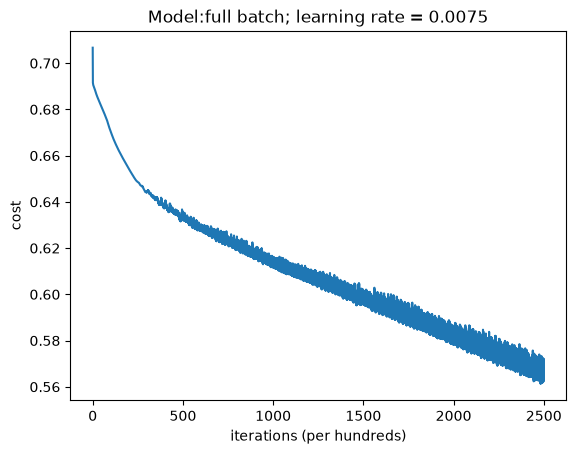

In [11]:
plot_costs(costs, "full batch", learning_rate)

In [12]:
import time
start_time = time.perf_counter()
input_features = X_train.shape[0]
iteration = 2500
learning_rate = 0.0075
mini_batch_size = 128
seed = 3
layer_dims_deep = [input_features, 30, 20, 10, 1]
parameter_deep, batch_costs, epoch_costs = dnn_model_mini_batch(
        X_train=X_train,
        Y_train=Y_train,
        X_test=X_test,
        Y_test=Y_test,
        layers_dims=layer_dims_deep,
        iteration=iteration,
        learning_rate=learning_rate,
        mini_batch_size=mini_batch_size,
        seed=seed,
        print_cost=True)

elapsed_minutes = (time.perf_counter() - start_time) / 60
print(f"Execution time: {elapsed_minutes:.2f} minutes")

Cost: 0.5173301077911953


Cost: 0.36547182354201474


Cost: 0.2579248444260576


Cost: 0.2912877337903609


Cost: 0.2891512765155313


...

Cost: 0.0002235927881580076


Cost: 0.00020290480367104075


Cost: 0.00018704135288291298


Cost: 0.0001716080756087775


Cost: 0.00015878414006522423
train_accuracy: 100.0%
test_accuracy: 62.0365793376174%
Execution time: 16.18 minutes


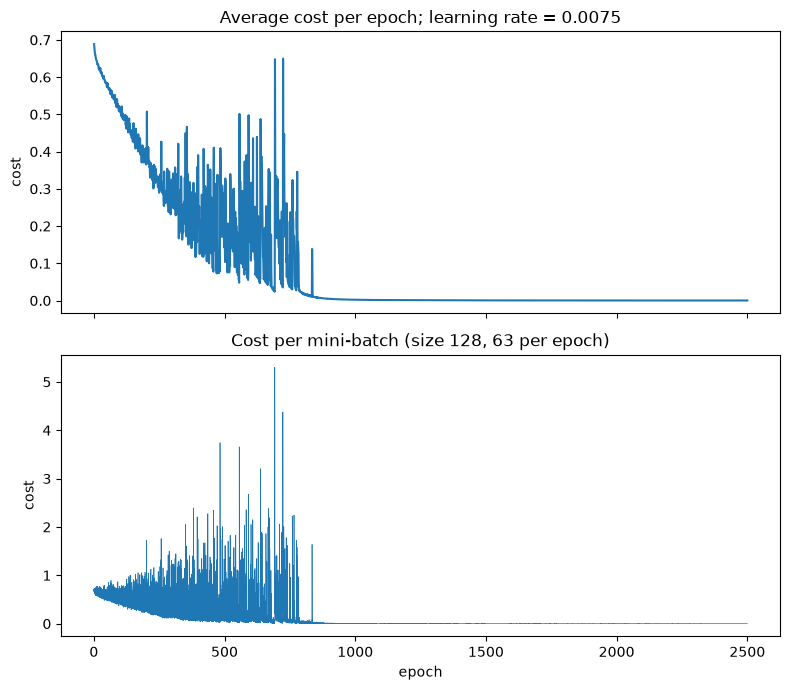

In [13]:
# epoch_costs has one point per epoch, batch_costs one point per mini-batch update.
# Put both on an epoch axis so the noise of each mini-batch lines up with its epoch.
batches_per_epoch = len(batch_costs) // len(epoch_costs)
epochs = np.arange(1, len(epoch_costs) + 1)
batch_steps = np.arange(1, len(batch_costs) + 1) / batches_per_epoch

fig, (ax_epoch, ax_batch) = plt.subplots(2, 1, sharex=True, figsize=(8, 7))

ax_epoch.plot(epochs, epoch_costs)
ax_epoch.set_title(f"Average cost per epoch; learning rate = {learning_rate}")
ax_epoch.set_ylabel("cost")

ax_batch.plot(batch_steps, batch_costs, linewidth=0.5)
ax_batch.set_title(f"Cost per mini-batch (size {mini_batch_size}, {batches_per_epoch} per epoch)")
ax_batch.set_xlabel("epoch")
ax_batch.set_ylabel("cost")

plt.tight_layout()
plt.show()

In [14]:
import time
start_time = time.perf_counter()
input_features = X_train.shape[0]
iteration = 900
learning_rate = 0.0075
mini_batch_size = 128
seed = 3
layer_dims_deep = [input_features, 30, 20, 10, 1]
parameter_deep, batch_costs, epoch_costs = dnn_model_mini_batch(
        X_train=X_train,
        Y_train=Y_train,
        X_test=X_test,
        Y_test=Y_test,
        layers_dims=layer_dims_deep,
        iteration=iteration,
        learning_rate=learning_rate,
        mini_batch_size=mini_batch_size,
        seed=seed,
        print_cost=True)

elapsed_minutes = (time.perf_counter() - start_time) / 60
print(f"Execution time: {elapsed_minutes:.2f} minutes")

Cost: 0.5173301077911953


Cost: 0.36547182354201474


Cost: 0.2579248444260576


Cost: 0.2912877337903609


Cost: 0.2891512765155313


Cost: 0.27269794594374774


Cost: 0.16765174646796446


Cost: 0.019252443795818728


Cost: 0.0047330216651629235
train_accuracy: 100.0%
test_accuracy: 61.5916955017301%
Execution time: 5.23 minutes


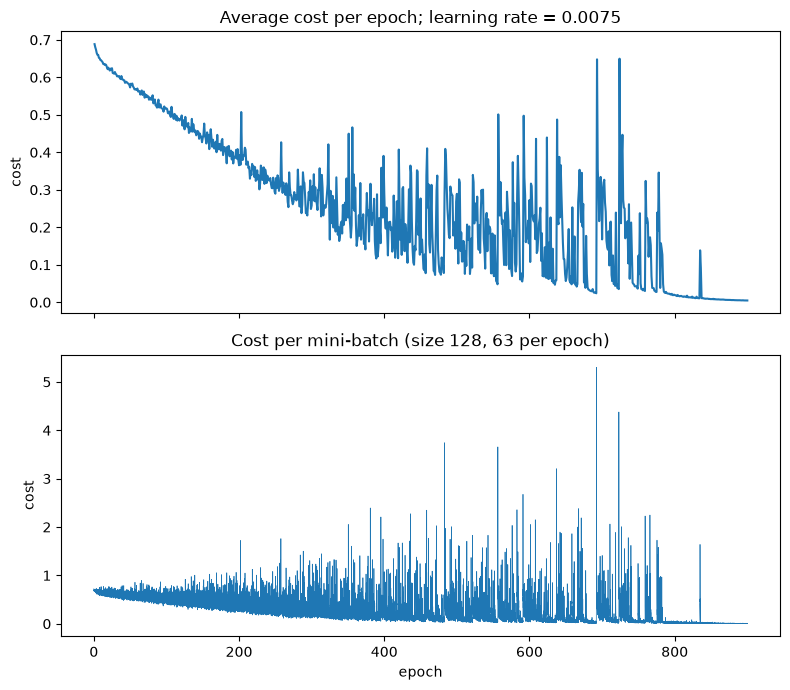

In [15]:
# epoch_costs has one point per epoch, batch_costs one point per mini-batch update.
# Put both on an epoch axis so the noise of each mini-batch lines up with its epoch.
batches_per_epoch = len(batch_costs) // len(epoch_costs)
epochs = np.arange(1, len(epoch_costs) + 1)
batch_steps = np.arange(1, len(batch_costs) + 1) / batches_per_epoch

fig, (ax_epoch, ax_batch) = plt.subplots(2, 1, sharex=True, figsize=(8, 7))

ax_epoch.plot(epochs, epoch_costs)
ax_epoch.set_title(f"Average cost per epoch; learning rate = {learning_rate}")
ax_epoch.set_ylabel("cost")

ax_batch.plot(batch_steps, batch_costs, linewidth=0.5)
ax_batch.set_title(f"Cost per mini-batch (size {mini_batch_size}, {batches_per_epoch} per epoch)")
ax_batch.set_xlabel("epoch")
ax_batch.set_ylabel("cost")

plt.tight_layout()
plt.show()

Deep Neural Network predict it's a cats picture


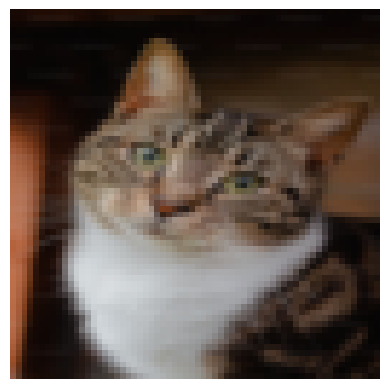

In [16]:
my_image = "cat_focus.png"
image, x_real_data = load_image(my_image)

plt.imshow(image)
plt.axis("off")

deep_prediction = classify(x_real_data, parameter_deep)
print(f"Deep Neural Network predict it's a {get_label(deep_prediction)} picture")